# Units, conversions and worked engineering examples

The Herschel–Bulkley (HB) law is used by communities that do not share a system of units. Drilling engineers quote yield stresses in pounds-force per hundred square feet and read field viscometers in dial degrees at speeds in revolutions per minute; the older rheological literature uses dynes per square centimeter; concrete technologists measure a slump-flow radius in millimetres and a cone volume in litres; and everyone else uses pascals and seconds. The consistency $K$ is the awkward one: its unit, Pa s$^n$, depends on the flow index, so a change of the *time* unit changes $K$ by a factor $60^n$ and a published $K$ cannot be compared between materials with different $n$. This notebook collects the conversions of Supplementary Table SVI into a small "unit-safe" parameter helper with tests, works through the three engineering examples of Supplementary Note S15 — a slurry pipeline (redone entirely in oilfield units, with the same $\Delta p$ as in SI), a slump-flow test and a settling cutting — and then turns to Sec. X of the review: what field practice does with the model, why the fitting window matters for drilling fluids, and what a shear-calibrated HB description can and cannot predict (Table XIII).

## Where this is in the review

* **Supplementary Note S15 A**, **Table SVI** — unit conversions: dyn/cm$^2$, lbf/100 ft$^2$, field-viscometer dial readings ($\times1.067\to$ lbf/100 ft$^2$ $=0.511$ Pa), viscometer speed (rpm $\times1.703\to$ s$^{-1}$), consistency units, cP.
* **Supplementary Note S15 B** — **Example 1** (slurry pipeline: $\sigma_w=20.0$ Pa, $\phi=0.25$, plug 12.5 mm, $\Delta p=401$ kPa, $U=1.27$ m/s, $n'=0.48$, $K'=2.18$ Pa s$^{0.48}$, $\mathrm{Re_{MR}}=776$), **Example 2** (slump flow: 23 Pa at $R=350$ mm, 50 Pa at 300 mm), **Example 3** (settling cutting: $\sigma_y\simeq3.51$ Pa, $Y_R$ threshold 0.0953); **Note S15 C** — glossary; **Note S19** — nomenclature (the principal symbols are Table V of the article, `data/tables/tableV_notation.csv`).
* **Sec. X A** *Choosing measurements for a prediction* — **Table XIII**; the drilling paragraph: API RP 13D, the fitting window of Saasen and Ytrehus (2020), rotation and eccentricity, restart. **Sec. XI**, sixth lesson — the two-speed viscometer and the readings at 511 and 1022 s$^{-1}$.
* **Sec. III B** and **Fig. 3** — the used drilling fluid whose flow index fell from 0.98 to 0.83 when fitted over 0–300 s$^{-1}$ instead of 0–1000 s$^{-1}$ (`data/hb_parameter_atlas.csv`, `data/figure_data/fig03_parameter_atlas.csv`).
* **Sec. IV C** — $\mathrm{Re_{MR}}$, **Eq. (9)**, and the reparameterization $\sigma=\sigma_y+A(\dot\gamma/\dot\gamma_*)^n$ with $A=K\dot\gamma_*^n$; **Sec. VI D** — the same form in Saasen and Ytrehus (2020), the form $\sigma_y[1+(\dot\gamma/\dot\gamma_y)^n]$ of Nelson and Ewoldt (2017), and the fitting procedures of Kelessidis et al. (2006).
* **Sec. VII E**, **Supplementary Note S11 B** — the spreading relation **Eq. (S26)** and its sensitivity **Eq. (S27)**; **Sec. VIII E**, **Table IV** — the yield number $Y_g$.
* **Supplementary Note S9 E** — $\Delta p=4\sigma_wL/D$, Fanning and Darcy factors.
* Scripts: `scripts/hb_prediction.py` (exact laminar pipe model; `pipe_flux`, `pressure_gradient`), `scripts/verify_equations.py` (its `run()` returns the `worked_examples` record); figure data `data/figure_data/figS7_friction_factor.csv`.
* Related notebooks: **02** (Example 1 step by step in SI and Example 3), **05** (a pumping example with the exact pipe model), **08** ($n'$, $K'$, $\mathrm{Re_{MR}}$ and Example 1 with the friction factor). Their derivations are not repeated here; this notebook adds the units, the oilfield route and the engineering context.

## Learning objectives

1. Convert HB parameters between SI, cgs and oilfield units, and between time units, without losing the factor $60^n$ or the stress factor in $K$.
2. Read a field viscometer: dial degrees to stress, rpm to shear rate, and the two-speed Bingham estimate that field practice still uses.
3. Reproduce Example 1 of Note S15 in SI and *entirely in oilfield units*, and obtain the same pressure drop.
4. Convert a slump-flow radius to a yield stress (Example 2) and quantify the fifth-power sensitivity, Eq. (S27).
5. Decide whether a cutting settles (Example 3) and see that a dimensionless criterion does not depend on the unit system.
6. Explain why the fitting window changes the HB parameters of a drilling fluid, why $A=K\dot\gamma_*^n$ is comparable between fluids when $K$ is not, and what Table XIII says a shear calibration supports.

## 1. Theory

### 1.1 Units of the three parameters

On the yielded branch $\sigma=\sigma_y+K\dot\gamma^n$ (Eq. (3)). The yield stress $\sigma_y$ is a stress and $n$ is a pure number, but the consistency must satisfy $[K]=[\sigma]\,[\dot\gamma]^{-n}$ — Pa s$^n$ in SI. Two consequences follow.

* **Changing the time unit changes $K$ by a power of the conversion factor.** If rates are expressed in min$^{-1}$, $\dot\gamma_{\rm min}=60\,\dot\gamma_{\rm s}$ and $K_{\rm s}\dot\gamma_{\rm s}^n=K_{\rm min}\dot\gamma_{\rm min}^n$ give
$$
K_{\rm min}=K_{\rm s}\,60^{-n},\qquad K_{\rm s}=K_{\rm min}\,60^{n}.
$$
The same rule applies to rpm: with the standard conversion $\dot\gamma\,[\mathrm{s^{-1}}]=1.703\,N\,[\mathrm{rpm}]$, a $K$ fitted to rates in rpm must be multiplied by $1.703^{-n}$ to refer to s$^{-1}$. For $n=0.7$ the factor $60^{0.7}$ is 17.6; forgetting it is not a small error.
* **$K$ is not comparable between materials of different $n$** (glossary, Note S15 C). The review's remedy (Sec. IV C; Saasen and Ytrehus, 2020) is a reference rate $\dot\gamma_*$ in the application window and the stress $A=K\dot\gamma_*^n$ that the viscous term contributes there:
$$
\sigma=\sigma_y+A\left(\frac{\dot\gamma}{\dot\gamma_*}\right)^n ,
$$
where $A$ has the units of a stress whatever $n$ is. Nelson and Ewoldt (2017) choose instead $\dot\gamma_y=(\sigma_y/K)^{1/n}$, the rate at which the flow stress is twice the yield stress: $\sigma=\sigma_y[1+(\dot\gamma/\dot\gamma_y)^n]$ (Sec. VI D).

### 1.2 Oilfield and older units (Table SVI)

| Quantity | Unit | SI equivalent |
|---|---|---|
| stress | dyn/cm$^2$ | 0.1 Pa |
| stress | lbf/100 ft$^2$ | 0.4788 Pa |
| stress | field-viscometer dial reading ($^\circ$) | $\approx1.067$ lbf/100 ft$^2$ $=0.511$ Pa |
| shear rate | viscometer speed (rpm) | $\times1.703=$ s$^{-1}$ (standard bob/rotor) |
| consistency | lbf s$^n$/100 ft$^2$ | $\times0.4788=$ Pa s$^n$ |
| consistency | dyn s$^n$/cm$^2$ | $\times0.1=$ Pa s$^n$ |
| viscosity | cP | $10^{-3}$ Pa s |

The stress factor is $1\ \mathrm{lbf}/(100\ \mathrm{ft^2})=4.448\ \mathrm{N}/9.290\ \mathrm{m^2}=0.4788$ Pa. A direct-indicating field viscometer (Fann type) is a concentric-cylinder instrument whose dial is graduated so that one degree is close to one lbf/100 ft$^2$; the conventional factor is 1.067, hence 0.511 Pa per degree. The speed factor 1.703 s$^{-1}$ per rpm is the Newtonian conversion for the standard rotor and bob (Table SVI gives the factor; the Couette conversion behind it is the subject of notebook 04). Because $0.511\ \mathrm{Pa}/511\ \mathrm{s^{-1}}=10^{-3}$ Pa s, the slope of the dial reading between 300 and 600 rpm (511 and 1022 s$^{-1}$) is a viscosity in cP — which is why the two-speed Bingham parameters of field practice, the plastic viscosity $\mu_p=\theta_{600}-\theta_{300}$ (cP) and the yield point $\theta_{300}-\mu_p$ (lbf/100 ft$^2$), can be read directly from the dial (Sec. XI, sixth lesson). Those two numbers are a straight line through two points of a curved flow curve; the review reports that such a yield point "can exceed the yield stress by several hundred percent" (Saasen and Ytrehus, 2020), and API RP 13D estimates the HB yield stress from the lowest-speed readings (Sec. X A), while current standards recommend a least-squares fit of all readings (Sec. XI).

### 1.3 The three worked examples (Note S15 B)

* **Example 1 — pressure drop in a slurry pipeline.** Momentum balance gives $\sigma_w=GR/2$ and $\Delta p=4\sigma_wL/D$; the laminar flow rate is Eq. (19), implicit in $\sigma_w$; the local index $n'$, consistency $K'$ and $\mathrm{Re_{MR}}=8\rho U^2/\sigma_w$ follow (Eq. (9); notebook 08).
* **Example 2 — yield stress from a slump-flow test.** In the spreading regime (final thickness $\ll$ radius) the static shape of a yield-stress layer gives (Roussel and Coussot, 2005; Eq. (S26))
$$
\sigma_y=\frac{225}{128\pi^2}\,\frac{\rho gV^2}{R^5},\qquad
\frac{\mathrm{d}\sigma_y}{\sigma_y}=\frac{\mathrm{d}\rho}{\rho}+2\frac{\mathrm{d}V}{V}-5\frac{\mathrm{d}R}{R}\quad\text{(S27)}.
$$
The result is independent of $K$ and $n$, and the fifth power makes it sensitive to the radius.
* **Example 3 — will a cutting settle?** A sphere is held at rest in an unbounded ideal no-slip Bingham material when $Y_g=3\sigma_y/(2\Delta\rho gR)$ exceeds about 0.143 (Beris et al., 1985); equivalently $Y_R=\sigma_y/(\Delta\rho gR)>0.0953$. The static limit is independent of $K$ and $n$; the settling speed above it is not.

### 1.4 What a shear calibration supports (Sec. X, Table XIII)

The review replaces "is this material an HB fluid?" by "which measurements must accompany a shear calibration for a given prediction?" For pressure loss in pipes and annuli the answer is: the shear calibration supports the integral resistance at moderate and high flow, *provided* the calibration window covers the operating wall shear rates, slip on the pipe material has been tested, and, for thixotropic fluids, the critical shear rate is known. Restart after shutdown, by contrast, is supported only as an ideal static threshold; the breakaway pressure needs a rest-time series and the system compliance. We return to the table in Sec. 8.

## 2. Setup

In [1]:
from pathlib import Path
import sys
import json
from dataclasses import dataclass
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq

# Locate the repository root whether the notebook is run from notebooks/ or from the root.
ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if (ROOT.parent / "data").exists() and not (ROOT / "data").exists() else ROOT
sys.path.insert(0, str(ROOT / "scripts"))
sys.dont_write_bytecode = True      # do not write __pycache__ files into scripts/

from hbstyle import C   # the article's colour palette and plot style (we never call hbstyle.save)
plt.rcParams["figure.dpi"] = 110
print("data folder found:", (ROOT / "data").is_dir())

import hb_prediction            # exact laminar pipe model: pipe_flux(sigma_w, R, sigma_y, K, n), pressure_gradient(Q, R, sigma_y, K, n)
from verify_equations import run as run_review_suite
review_examples = run_review_suite()["worked_examples"]   # the review's own worked-example record (computed live, < 1 s)

data folder found: True


## 3. A unit-safe HB parameter helper

We build the conversion factors from the definitions of the units (pound-force, foot, US gallon, inch) rather than typing rounded numbers, and check that they reproduce Table SVI. The class `HBParams` stores the triplet in SI and converts on the way in and out; the only place where $n$ enters a conversion — the time unit of $K$ — is isolated in two lines.

In [2]:
# Base definitions (exact by definition of the units)
LBF = 0.45359237 * 9.80665          # N, pound-force
FT, IN = 0.3048, 0.0254              # m
GAL = 3.785411784e-3                 # m^3, US gallon
PSI = LBF / IN**2                    # Pa
LBF_100FT2 = LBF / (100 * FT**2)     # Pa, pound-force per hundred square feet
DIAL = 1.067 * LBF_100FT2            # Pa per field-viscometer dial degree
RPM_TO_S = 1.703                     # s^-1 per rpm, standard rotor/bob (Table SVI)
PPG = 0.45359237 / GAL               # kg/m^3 per lb/gal (pounds-mass per US gallon)
SLUG = 0.45359237 * 9.80665 / 0.3048 # kg, the mass unit of the lbf-ft-s system (slug = lbf s^2/ft)

STRESS = {"Pa": 1.0, "kPa": 1e3, "dyn/cm2": 0.1, "lbf/100ft2": LBF_100FT2, "lbf/ft2": LBF / FT**2, "psi": PSI, "dial": DIAL}
TIME = {"s": 1.0, "min": 60.0}                              # seconds per time unit
RATE = {"1/s": 1.0, "1/min": 1 / 60, "rpm": RPM_TO_S}        # s^-1 per rate unit

print(f"1 lbf/100 ft^2 = {LBF_100FT2:.4f} Pa      (Table SVI: 0.4788 Pa)")
print(f"1 dial degree  = {DIAL:.3f} Pa          (Table SVI: 0.511 Pa)")
print(f"1 psi          = {PSI:.1f} Pa")
print(f"1 lb/gal       = {PPG:.2f} kg/m^3")
assert np.isclose(LBF_100FT2, 0.4788, atol=5e-5) and np.isclose(DIAL, 0.511, atol=5e-4) and np.isclose(0.1 * STRESS["Pa"], STRESS["dyn/cm2"])
assert np.isclose(DIAL / (300 * RPM_TO_S), 1e-3, rtol=2e-3)   # one dial degree per 300 rpm is one cP (Sec. 1.2)

1 lbf/100 ft^2 = 0.4788 Pa      (Table SVI: 0.4788 Pa)
1 dial degree  = 0.511 Pa          (Table SVI: 0.511 Pa)
1 psi          = 6894.8 Pa
1 lb/gal       = 119.83 kg/m^3


In [3]:
@dataclass(frozen=True)
class HBParams:
    '''Herschel-Bulkley triplet stored in SI: sigma_y [Pa], K [Pa s^n], n [-].'''
    sigma_y: float
    K: float
    n: float

    @classmethod
    def from_units(cls, sigma_y, K, n, stress_unit="Pa", time_unit="s"):
        '''Build from sigma_y [stress_unit], K [stress_unit * time_unit^n] and n.'''
        f, t = STRESS[stress_unit], TIME[time_unit]
        return cls(sigma_y * f, K * f * t**n, n)        # K [Pa s^n] = K [unit * tu^n] * f * (seconds per tu)^n

    def sigma_y_in(self, stress_unit="Pa"):
        return self.sigma_y / STRESS[stress_unit]

    def K_in(self, stress_unit="Pa", time_unit="s"):
        return self.K / STRESS[stress_unit] / TIME[time_unit] ** self.n

    def stress(self, rate, rate_unit="1/s", stress_unit="Pa"):
        '''Flow stress on the yielded branch at a shear rate given in any supported unit.'''
        gd = np.asarray(rate, float) * RATE[rate_unit]
        return (self.sigma_y + self.K * gd**self.n) / STRESS[stress_unit]

    def A(self, rate_star, rate_unit="1/s"):
        '''Stress amplitude A = K gdot_*^n at the reference rate (Sec. IV C).'''
        return self.K * (rate_star * RATE[rate_unit]) ** self.n

    def rate_y(self):
        '''Nelson-Ewoldt rate gdot_y = (sigma_y/K)^(1/n), where the flow stress is twice the yield stress.'''
        return (self.sigma_y / self.K) ** (1 / self.n)

    def describe(self, stress_unit="Pa", time_unit="s"):
        tu = "" if time_unit == "s" else f" ({time_unit})"
        return (f"sigma_y = {self.sigma_y_in(stress_unit):.4g} {stress_unit}, "
                f"K = {self.K_in(stress_unit, time_unit):.4g} {stress_unit} {time_unit}^{self.n:g}, n = {self.n:g}")

slurry = HBParams(5.0, 0.5, 0.7)              # Example 1 of Note S15, in SI
print(slurry.describe())
print(slurry.describe("lbf/100ft2"))
print(slurry.describe("dyn/cm2", "min"))

sigma_y = 5 Pa, K = 0.5 Pa s^0.7, n = 0.7
sigma_y = 10.44 lbf/100ft2, K = 1.044 lbf/100ft2 s^0.7, n = 0.7
sigma_y = 50 dyn/cm2, K = 0.2846 dyn/cm2 min^0.7, n = 0.7


### 3.1 Tests of the helper

Each test is an identity that a wrong conversion would break: a round trip must return the input; the flow stress at a given physical rate must not depend on the units in which $K$ and the rate are expressed; and the two mutants — $K$ converted as if it were a stress only (time factor forgotten) and the time factor applied in the wrong direction — must be rejected.

In [4]:
rng = np.random.default_rng(2026)
for _ in range(50):
    ty, K, n = rng.uniform(0.1, 50), rng.uniform(0.01, 20), rng.uniform(0.2, 1.5)
    p = HBParams(ty, K, n)
    for su in STRESS:
        for tu in TIME:
            q = HBParams.from_units(p.sigma_y_in(su), p.K_in(su, tu), n, su, tu)       # round trip
            assert np.isclose(q.sigma_y, ty, rtol=1e-12) and np.isclose(q.K, K, rtol=1e-12)
    for ru in RATE:                                                                     # same physical rate, any rate unit
        g = 37.0                                                                         # s^-1
        assert np.isclose(p.stress(g / RATE[ru], ru), ty + K * g**n, rtol=1e-12)
print("round trips in all stress and time units, and stress at a fixed physical rate in all rate units: pass")

# the factor 60^n, explicitly
K_min = slurry.K_in("Pa", "min")
print(f"K = {slurry.K} Pa s^0.7 = {K_min:.5f} Pa min^0.7  (ratio 60^0.7 = {60**0.7:.2f})")
assert np.isclose(K_min, 0.5 * 60**-0.7) and np.isclose(K_min * (60 * 100) ** 0.7, 0.5 * 100**0.7)

# mutants
K_mutant_1 = slurry.K                                   # 'K is a stress, so only the stress factor matters': time factor forgotten
K_mutant_2 = slurry.K * 60**0.7                         # time factor applied in the wrong direction
for name, Kbad in [("time factor forgotten", K_mutant_1), ("time factor inverted", K_mutant_2)]:
    stress_bad = slurry.sigma_y + Kbad * (60 * 100) ** 0.7       # rate 100 s^-1 expressed in min^-1
    assert not np.isclose(stress_bad, slurry.stress(100.0)), name
    print(f"  mutant caught ({name}): stress at 100 1/s would be {stress_bad:.1f} Pa instead of {slurry.stress(100.0):.2f} Pa")

round trips in all stress and time units, and stress at a fixed physical rate in all rate units: pass
K = 0.5 Pa s^0.7 = 0.02846 Pa min^0.7  (ratio 60^0.7 = 17.57)
  mutant caught (time factor forgotten): stress at 100 1/s would be 225.6 Pa instead of 17.56 Pa
  mutant caught (time factor inverted): stress at 100 1/s would be 3881.0 Pa instead of 17.56 Pa


### 3.2 Reading a field viscometer (beyond the article's text, using Table SVI)

A six-speed field viscometer gives dial readings $\theta_N$ at $N=3,6,100,200,300,600$ rpm. We synthesize such readings from an HB fluid — the *used drilling fluid* of Saasen and Ytrehus (2020) as listed in the review's parameter atlas (the 0–300 s$^{-1}$ fit: $\sigma_y=0.2$ Pa, $K=0.0548$ Pa s$^{0.83}$, $n=0.83$) — round them to half a degree as a dial would, and apply the two-speed Bingham estimate of Sec. 1.2 and the lowest-speed extrapolation. This is an illustration of how the estimators behave on a known HB fluid, not a reproduction of their measurements.

In [5]:
atlas = pd.read_csv(ROOT / "data" / "hb_parameter_atlas.csv")
rows = atlas[atlas.material.str.startswith("Used drilling fluid")].set_index("material")
print(rows[["sigma_y_Pa", "n", "K_Pa_s_n", "source_key", "source_location"]].to_string())
fit300 = HBParams(float(rows.loc["Used drilling fluid (fit 0-300 1/s)", "sigma_y_Pa"]),
                  float(rows.loc["Used drilling fluid (fit 0-300 1/s)", "K_Pa_s_n"]), float(rows.loc["Used drilling fluid (fit 0-300 1/s)", "n"]))
fit1000 = HBParams(float(rows.loc["Used drilling fluid (fit 0-1000 1/s)", "sigma_y_Pa"]),
                   float(rows.loc["Used drilling fluid (fit 0-1000 1/s)", "K_Pa_s_n"]), float(rows.loc["Used drilling fluid (fit 0-1000 1/s)", "n"]))

speeds = np.array([3, 6, 100, 200, 300, 600])                                  # rpm
theta = np.round(fit300.stress(speeds, "rpm", "dial") * 2) / 2                 # dial readings, to the nearest half degree
print("\nsynthetic dial readings (degrees) from the 0-300 1/s triplet:")
print("  " + "   ".join(f"{N:3d} rpm: {t:5.1f}" for N, t in zip(speeds, theta)))

th = dict(zip(speeds, theta))
PV_cP = th[600] - th[300]                                   # plastic viscosity, cP (slope between 511 and 1022 1/s)
YP = th[300] - PV_cP                                        # yield point, lbf/100 ft^2 (dial degrees taken as lbf/100 ft^2, as in field practice)
YP_Pa = (2 * th[300] - th[600]) * DIAL                       # the same intercept converted exactly
LSYP_Pa = (2 * th[3] - th[6]) * DIAL                         # linear extrapolation of the two lowest readings to zero speed
th_exact = dict(zip(speeds, fit300.stress(speeds, "rpm", "dial")))   # the same without the half-degree rounding
LSYP_exact = (2 * th_exact[3] - th_exact[6]) * DIAL
print(f"\ntwo-speed Bingham estimate: PV = {PV_cP:.1f} cP, YP = {YP:.1f} (dial degrees, read as lbf/100 ft^2) = {YP_Pa:.2f} Pa")
print(f"HB yield stress of the fluid:                   sigma_y = {fit300.sigma_y:.2f} Pa  -> the two-speed yield point is {YP_Pa / fit300.sigma_y:.0f} x too large")
print(f"extrapolation of the 3 and 6 rpm readings:      {LSYP_Pa:.2f} Pa from the half-degree dial, {LSYP_exact:.2f} Pa from unrounded readings"
      "\n                                                (the kind of low-speed estimate API RP 13D uses)")

                                      sigma_y_Pa       n  K_Pa_s_n         source_key source_location
material                                                                                             
Used drilling fluid (fit 0-1000 1/s)         0.2  0.9806    0.0229  SaasenYtrehus2020         Table 1
Used drilling fluid (fit 0-300 1/s)          0.2  0.8269    0.0548  SaasenYtrehus2020         Table 1

synthetic dial readings (degrees) from the 0-300 1/s triplet:
    3 rpm:   1.0     6 rpm:   1.0   100 rpm:   8.0   200 rpm:  13.5   300 rpm:  19.0   600 rpm:  33.5

two-speed Bingham estimate: PV = 14.5 cP, YP = 4.5 (dial degrees, read as lbf/100 ft^2) = 2.30 Pa
HB yield stress of the fluid:                   sigma_y = 0.20 Pa  -> the two-speed yield point is 11 x too large
extrapolation of the 3 and 6 rpm readings:      0.51 Pa from the half-degree dial, 0.25 Pa from unrounded readings
                                                (the kind of low-speed estimate API RP 13D uses)


The straight line through the 300- and 600-rpm readings has an intercept an order of magnitude above the true $\sigma_y$ of this shear-thinning fluid. The low-speed extrapolation is of the right order, but at a yield stress of 0.2 Pa it is limited by the resolution of the dial: half a degree is 0.26 Pa, more than the quantity being estimated — "field viscometer readings at a few nominal speeds poorly constrain the intercept" (Sec. X A). The two-speed numbers are not wrong as a *description of the dial between 511 and 1022 s$^{-1}$* — they are wrong as a *yield stress*, and the review's Sec. XI explains why they persist: "standards encode the technology of the time at which they were written".

## 4. Example 1 — the slurry pipeline, in SI and entirely in oilfield units

Note S15 B, Example 1: $\sigma_y=5$ Pa, $K=0.5$ Pa s$^{0.7}$, $n=0.7$, $\rho=1200$ kg/m$^3$, $Q=10$ L/s, $L=500$ m, $D=100$ mm. Notebooks 02 and 08 derive $\sigma_w$, $\phi$, the plug radius, $\Delta p$, $U$, $n'$, $K'$ and $\mathrm{Re_{MR}}$ step by step; here we take the SI solution from `hb_prediction` as the reference and then repeat the whole calculation in oilfield units.

### 4.1 Reference solution in SI

In [6]:
rho_SI, Q_SI, L_SI, D_SI = 1200.0, 0.010, 500.0, 0.100
R_SI = D_SI / 2
G_SI = hb_prediction.pressure_gradient(Q_SI, R_SI, slurry.sigma_y, slurry.K, slurry.n)   # Pa/m, Eq. (19) inverted
tw_SI = G_SI * R_SI / 2
U_SI = Q_SI / (np.pi * R_SI**2)
dp_SI = 4 * tw_SI * L_SI / D_SI
Re_SI = 8 * rho_SI * U_SI**2 / tw_SI                                              # Eq. (9) in laminar flow
si = {"sigma_w (Pa)": tw_SI, "phi": slurry.sigma_y / tw_SI, "plug radius (mm)": 1e3 * R_SI * slurry.sigma_y / tw_SI,
      "Delta p (kPa)": dp_SI / 1e3, "U (m/s)": U_SI, "Re_MR": Re_SI}
printed = {"sigma_w (Pa)": (20.0, 1), "phi": (0.25, 2), "plug radius (mm)": (12.5, 1), "Delta p (kPa)": (401, 0), "U (m/s)": (1.27, 2), "Re_MR": (776, 0)}
for k, v in si.items():
    print(f"{k:18s} = {v:10.4f}   printed: {printed[k][0]}")
    assert round(v, printed[k][1]) == printed[k][0], k
stored = review_examples["pipe"]
assert np.isclose(stored["wall_stress_Pa"], tw_SI, rtol=1e-9) and np.isclose(stored["Re_MR"], Re_SI, rtol=1e-9)
print("SI solution reproduces the printed values of Example 1 and the record of scripts/verify_equations.py.")

sigma_w (Pa)       =    20.0485   printed: 20.0
phi                =     0.2494   printed: 0.25
plug radius (mm)   =    12.4697   printed: 12.5
Delta p (kPa)      =   400.9705   printed: 401
U (m/s)            =     1.2732   printed: 1.27
Re_MR              =   776.2633   printed: 776
SI solution reproduces the printed values of Example 1 and the record of scripts/verify_equations.py.


### 4.2 The same problem as a field engineer would receive it

The data arrive in oilfield units: yield stress and consistency in lbf/100 ft$^2$ (and lbf s$^n$/100 ft$^2$), density in lb/gal, flow rate in gal/min, diameter in inches, length in feet; the answer is wanted in psi. We first convert the problem statement (these are the values the engineer would be given), then solve it in two ways.

In [7]:
ty_oil = slurry.sigma_y_in("lbf/100ft2")          # lbf/100 ft^2
K_oil = slurry.K_in("lbf/100ft2")                 # lbf s^0.7/100 ft^2
rho_ppg = rho_SI / PPG                            # lb/gal
Q_gpm = Q_SI / GAL * 60                           # gal/min
D_in = D_SI / IN                                  # inches
L_ft = L_SI / FT                                  # feet
print(f"Problem in oilfield units: sigma_y = {ty_oil:.2f} lbf/100 ft^2, K = {K_oil:.3f} lbf s^0.7/100 ft^2, n = 0.7, "
      f"rho = {rho_ppg:.2f} lb/gal,\n                           Q = {Q_gpm:.1f} gal/min, D = {D_in:.3f} in, L = {L_ft:.0f} ft")

Problem in oilfield units: sigma_y = 10.44 lbf/100 ft^2, K = 1.044 lbf s^0.7/100 ft^2, n = 0.7, rho = 10.01 lb/gal,
                           Q = 158.5 gal/min, D = 3.937 in, L = 1640 ft


**Route A: convert to SI, solve, convert back.** This is the safe route whenever a validated SI implementation exists.

In [8]:
p_A = HBParams.from_units(ty_oil, K_oil, 0.7, "lbf/100ft2", "s")
Q_A, R_A, L_A, rho_A = Q_gpm * GAL / 60, D_in * IN / 2, L_ft * FT, rho_ppg * PPG
G_A = hb_prediction.pressure_gradient(Q_A, R_A, p_A.sigma_y, p_A.K, p_A.n)
tw_A = G_A * R_A / 2
dp_A = 4 * tw_A * L_A / (2 * R_A)
U_A = Q_A / (np.pi * R_A**2)
print(f"Route A: sigma_w = {tw_A / LBF_100FT2:.2f} lbf/100 ft^2, plug radius = {R_A * p_A.sigma_y / tw_A / IN:.3f} in, "
      f"U = {U_A / FT:.2f} ft/s,\n         Delta p = {dp_A / PSI:.2f} psi = {dp_A / 1e3:.1f} kPa  "
      f"({dp_A / PSI / (L_ft / 1000):.1f} psi per 1000 ft), Re_MR = {8 * rho_A * U_A**2 / tw_A:.0f}")
assert np.isclose(dp_A, dp_SI, rtol=1e-12)

Route A: sigma_w = 41.87 lbf/100 ft^2, plug radius = 0.491 in, U = 4.18 ft/s,
         Delta p = 58.16 psi = 401.0 kPa  (35.5 psi per 1000 ft), Re_MR = 776


**Route B: solve in a consistent oilfield-derived system.** Eq. (19) holds in *any* consistent set of units; what is not consistent is the mixture lbf/100 ft$^2$, inches, gallons per minute and lb/gal. We therefore express everything in the **lbf–ft–s** system — stress in lbf/ft$^2$, $K$ in lbf s$^n$/ft$^2$, lengths in ft, $Q$ in ft$^3$/s — and call the *same* pipe model, which only requires consistency (its docstring says SI, but no SI constant appears in it). The density must then be in slugs per cubic foot (1 slug $=1$ lbf s$^2$/ft $=14.59$ kg): lb/gal and lbm/ft$^3$ are *mass* densities, and a Reynolds number formed with lbm/ft$^3$ in the lbf–ft–s system would be off by $g=32.17$ ft/s$^2$.

In [9]:
ty_B = ty_oil / 100.0                              # lbf/ft^2
K_B = K_oil / 100.0                                # lbf s^0.7/ft^2
R_B, L_B = D_in / 12 / 2, L_ft                     # ft
Q_B = Q_gpm * (GAL / FT**3) / 60                   # ft^3/s
rho_B = rho_ppg * PPG / SLUG * FT**3               # slug/ft^3
G_B = hb_prediction.pressure_gradient(Q_B, R_B, ty_B, K_B, 0.7)       # lbf/ft^2 per ft
tw_B = G_B * R_B / 2                                                    # lbf/ft^2
dp_B = 4 * tw_B * L_B / (2 * R_B)                                       # lbf/ft^2
U_B = Q_B / (np.pi * R_B**2)                                            # ft/s
Re_B = 8 * rho_B * U_B**2 / tw_B                                        # slug/ft^3 * ft^2/s^2 / (lbf/ft^2): dimensionless
print(f"Route B (lbf-ft-s): sigma_w = {tw_B * 100:.2f} lbf/100 ft^2, Delta p = {dp_B:.1f} lbf/ft^2 = {dp_B / 144:.2f} psi, "
      f"U = {U_B:.2f} ft/s, Re_MR = {Re_B:.0f}")
assert np.isclose(dp_B / 144 * PSI, dp_SI, rtol=1e-10) and np.isclose(Re_B, Re_SI, rtol=1e-10) and np.isclose(tw_B * 100 * LBF_100FT2, tw_SI, rtol=1e-10)
print(f"Both routes give Delta p = {dp_SI / 1e3:.1f} kPa = {dp_SI / PSI:.2f} psi and Re_MR = {Re_SI:.0f}: a dimensionless group is the same in every consistent system.")

Route B (lbf-ft-s): sigma_w = 41.87 lbf/100 ft^2, Delta p = 8374.4 lbf/ft^2 = 58.16 psi, U = 4.18 ft/s, Re_MR = 776
Both routes give Delta p = 401.0 kPa = 58.16 psi and Re_MR = 776: a dimensionless group is the same in every consistent system.


**What goes wrong without conversion.** Three common mistakes, each caught by the SI reference:

In [10]:
wrong = {}
# (i) oilfield numbers fed straight into the SI model
wrong["raw oilfield numbers in the SI model"] = 4 * hb_prediction.pressure_gradient(Q_gpm, D_in / 2, ty_oil, K_oil, 0.7) * (D_in / 2) / 2 * L_ft / D_in
# (ii) K converted as a stress but rates taken per minute without the 60^n factor
p_bad = HBParams(slurry.sigma_y, slurry.K, 0.7)                     # correct K ...
Q_per_min = Q_SI * 60                                                 # ... but Q in m^3/min: rates are then per minute, and K should be K_min = K 60^-n
wrong["rates per minute, K left in Pa s^n"] = 4 * hb_prediction.pressure_gradient(Q_per_min, R_SI, p_bad.sigma_y, p_bad.K, 0.7) * R_SI / 2 * L_SI / D_SI
# (iii) density in lbm/ft^3 used in place of slug/ft^3 in the lbf-ft-s system (affects Re_MR, not Delta p)
Re_wrong = 8 * (rho_ppg * PPG / SLUG * FT**3 * 32.174) * U_B**2 / tw_B
for k, v in wrong.items():
    print(f"  {k:45s}: Delta p = {v / 1e3:10.1f} 'kPa'  (correct: {dp_SI / 1e3:.1f} kPa)")
print(f"  {'density in lbm/ft^3 used in place of slug/ft^3':45s}: Re_MR = {Re_wrong:.0f}  (correct: {Re_SI:.0f}; factor g = 32.17)")
assert all(not np.isclose(v, dp_SI, rtol=0.01) for v in wrong.values()) and not np.isclose(Re_wrong, Re_SI, rtol=0.01)

  raw oilfield numbers in the SI model         : Delta p =       40.3 'kPa'  (correct: 401.0 kPa)
  rates per minute, K left in Pa s^n           : Delta p =     4929.2 'kPa'  (correct: 401.0 kPa)
  density in lbm/ft^3 used in place of slug/ft^3: Re_MR = 24975  (correct: 776; factor g = 32.17)


The second mistake is instructive: with $Q$ in m$^3$/min the wall shear rate is 60 times larger in number, so the model demands a viscous stress $K(60\dot\gamma)^n$ that is $60^{0.7}=17.6$ times too large — and the inverted pressure drop follows. Keeping $K$ in SI and feeding rates in other units is the most frequent way to lose the factor $60^n$.

### 4.3 Example 1 on the friction-factor chart

The laminar line of Supplementary Fig. S7 is $f_F=16/\mathrm{Re_{MR}}$. We check that the operating point of Example 1 lies on the stored laminar line of `data/figure_data/figS7_friction_factor.csv` (notebook 08 reproduces the whole figure).

In [11]:
fdS7 = pd.read_csv(ROOT / "data" / "figure_data" / "figS7_friction_factor.csv", comment="#")
lam = fdS7[fdS7.series == "laminar, $f_F=16/\\mathrm{Re_{MR}}$"].sort_values("x")
fF = tw_SI / (0.5 * rho_SI * U_SI**2)
f_line = np.exp(np.interp(np.log(Re_SI), np.log(lam.x), np.log(lam.y)))     # log-log interpolation of the stored line
assert lam.x.min() < Re_SI < lam.x.max() and np.isclose(fF, 16 / Re_SI, rtol=1e-12) and np.isclose(fF, f_line, rtol=1e-8)
print(f"Example 1: Re_MR = {Re_SI:.0f}, f_F = 2 sigma_w/(rho U^2) = {fF:.5f} = 16/Re_MR, on the laminar line stored for Fig. S7 (rtol 1e-8).")
print(f"Pressure drop from the friction factor: 2 f_F rho U^2 L/D = {2 * fF * rho_SI * U_SI**2 * L_SI / D_SI / 1e3:.1f} kPa  (Darcy convention would need f_D = 4 f_F = {4 * fF:.4f})")

Example 1: Re_MR = 776, f_F = 2 sigma_w/(rho U^2) = 0.02061 = 16/Re_MR, on the laminar line stored for Fig. S7 (rtol 1e-8).
Pressure drop from the friction factor: 2 f_F rho U^2 L/D = 401.0 kPa  (Darcy convention would need f_D = 4 f_F = 0.0824)


## 5. Example 2 — yield stress of concrete from a slump-flow test

Self-compacting concrete, $\rho=2300$ kg/m$^3$, cone volume $V=5.5$ L, final spread radius $R=350$ mm. Eq. (S26) gives $\sigma_y=225\rho gV^2/(128\pi^2R^5)$; the review quotes 23 Pa, and 50 Pa for a spread of 300 mm. The helper handles the litres and millimetres; the coefficient $C=225/(128\pi^2)$ itself is verified by quadrature in notebook 17.

In [12]:
C_spread = 225 / (128 * np.pi**2)
g = 9.81
def slump_yield_stress(rho, V_litre, R_mm):
    '''Eq. (S26) with the volume in litres and the radius in millimetres.'''
    return C_spread * rho * g * (V_litre * 1e-3) ** 2 / (R_mm * 1e-3) ** 5

ty_350, ty_300 = slump_yield_stress(2300.0, 5.5, 350.0), slump_yield_stress(2300.0, 5.5, 300.0)
print(f"R = 350 mm: sigma_y = {ty_350:.1f} Pa (printed: 23 Pa);  R = 300 mm: sigma_y = {ty_300:.1f} Pa (printed: 50 Pa)")
assert round(ty_350) == 23 and round(ty_300) == 50
spread = review_examples["spread"]
assert np.isclose(spread["yield_stress_R035_Pa"], ty_350, rtol=1e-9) and np.isclose(spread["yield_stress_R030_Pa"], ty_300, rtol=1e-9)
print("both values agree with the record of scripts/verify_equations.py; in oilfield units:", f"{ty_350 / LBF_100FT2:.1f} and {ty_300 / LBF_100FT2:.1f} lbf/100 ft^2")

# sensitivity, Eq. (S27): d ln sigma_y = d ln rho + 2 d ln V - 5 d ln R, checked by finite differences
h = 1e-6
dR = (np.log(slump_yield_stress(2300, 5.5, 350 * (1 + h))) - np.log(ty_350)) / h
dV = (np.log(slump_yield_stress(2300, 5.5 * (1 + h), 350)) - np.log(ty_350)) / h
drho = (np.log(slump_yield_stress(2300 * (1 + h), 5.5, 350)) - np.log(ty_350)) / h
print(f"logarithmic sensitivities: rho {drho:+.4f}, V {dV:+.4f}, R {dR:+.4f}   (Eq. (S27): +1, +2, -5)")
assert np.isclose(drho, 1, atol=1e-4) and np.isclose(dV, 2, atol=1e-4) and np.isclose(dR, -5, atol=1e-4)
print(f"a 10 mm error in a 350 mm spread (2.9 %) changes sigma_y by about {5 * 10 / 350 * 100:.0f} %; "
      f"with independent 1 % errors in rho, V and R the relative standard deviation is about {np.sqrt(1 + 4 + 25):.1f} %")

R = 350 mm: sigma_y = 23.1 Pa (printed: 23 Pa);  R = 300 mm: sigma_y = 50.0 Pa (printed: 50 Pa)
both values agree with the record of scripts/verify_equations.py; in oilfield units: 48.3 and 104.5 lbf/100 ft^2
logarithmic sensitivities: rho +1.0000, V +2.0000, R -5.0000   (Eq. (S27): +1, +2, -5)
a 10 mm error in a 350 mm spread (2.9 %) changes sigma_y by about 14 %; with independent 1 % errors in rho, V and R the relative standard deviation is about 5.5 %


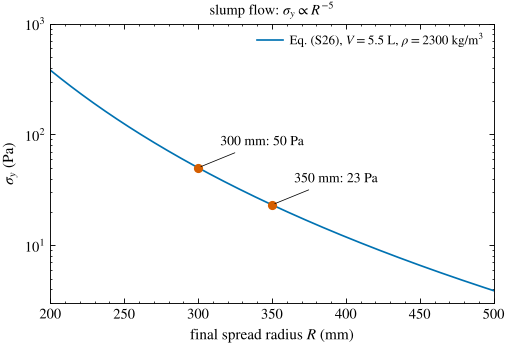

In [13]:
R_mm = np.linspace(200, 500, 300)
fig, ax = plt.subplots(figsize=(5.2, 3.3))
ax.semilogy(R_mm, slump_yield_stress(2300.0, 5.5, R_mm), color=C["blue"], label=r"Eq. (S26), $V=5.5$ L, $\rho=2300$ kg/m$^3$")
for Rp, tyv in [(350, ty_350), (300, ty_300)]:
    ax.plot([Rp], [tyv], "o", color=C["red"], ms=5)
    ax.annotate(f"{Rp} mm: {tyv:.0f} Pa", (Rp, tyv), xytext=(Rp + 15, tyv * 1.6), fontsize=9, arrowprops=dict(arrowstyle="-", lw=0.5))
ax.set(xlabel="final spread radius $R$ (mm)", ylabel=r"$\sigma_y$ (Pa)", xlim=(200, 500), ylim=(3, 1000))
ax.legend(fontsize=8.5)
ax.set_title(r"slump flow: $\sigma_y\propto R^{-5}$", fontsize=9.5)
plt.show()

The estimate is independent of $K$ and $n$ (only the transient would constrain them), and the fifth power makes it both sensitive and error-prone. Note S11 B adds that the measurement sensitivity is not the whole uncertainty: if the layer is not shallow, if capillarity or basal slip matters, or if the final state is not marginal, the coefficient itself changes — "adding more decimal places to the measured radius does not remedy an invalid shape model".

## 6. Example 3 — will a cutting settle?

A 5 mm cutting ($R=2.5$ mm) with $\Delta\rho=1500$ kg/m$^3$ is arrested when $Y_g=3\sigma_y/(2\Delta\rho gR)>0.143$. Notebook 02 discusses the criterion; here we compute the threshold in SI and in oilfield units and verify that $Y_g$ is the same number in both.

In [14]:
R_p, drho = 0.0025, 1500.0
ty_crit = 0.143 * 2 * drho * g * R_p / 3                            # Pa
sphere = review_examples["sphere"]
print(f"sigma_y needed to hold the cutting: {ty_crit:.2f} Pa = {ty_crit / LBF_100FT2:.2f} lbf/100 ft^2 (printed: 3.51 Pa); Y_R threshold = {0.143 / 1.5:.4f} (printed: 0.0953)")
assert round(ty_crit, 2) == 3.51 and np.isclose(ty_crit, sphere["yield_stress_Pa"], rtol=1e-9) and round(0.143 / 1.5, 4) == 0.0953

# the same criterion evaluated in the lbf-ft-s system
Yg_SI = 3 * ty_crit / (2 * drho * g * R_p)
Yg_oil = 3 * (ty_crit / (LBF / FT**2)) / (2 * (drho / SLUG * FT**3) * (g / FT) * (R_p / FT))      # lbf/ft^2, slug/ft^3, ft/s^2, ft
assert np.isclose(Yg_SI, Yg_oil, rtol=1e-12)
print(f"Y_g = {Yg_SI:.4f} in SI and {Yg_oil:.4f} in lbf-ft-s units: dimensionless, as it must be.")
print(f"The slurry of Example 1 (sigma_y = 5 Pa) has Y_g = {3 * 5.0 / (2 * drho * g * R_p):.3f} > 0.143 for this cutting at rest; "
      "the review warns that shape, walls, elasticity, thixotropy and imposed shear limit the transfer of this screening estimate.")

sigma_y needed to hold the cutting: 3.51 Pa = 7.32 lbf/100 ft^2 (printed: 3.51 Pa); Y_R threshold = 0.0953 (printed: 0.0953)
Y_g = 0.1430 in SI and 0.1430 in lbf-ft-s units: dimensionless, as it must be.
The slurry of Example 1 (sigma_y = 5 Pa) has Y_g = 0.204 > 0.143 for this cutting at rest; the review warns that shape, walls, elasticity, thixotropy and imposed shear limit the transfer of this screening estimate.


## 7. Drilling practice: the fitting window and the reparameterization (Sec. X A, Sec. VI D)

### 7.1 Two triplets for one fluid

Saasen and Ytrehus (2020) fitted the same used drilling fluid over 0–1000 s$^{-1}$ and over 0–300 s$^{-1}$, the range that an annulus actually experiences ("rarely exceed about 250 s$^{-1}$"). The consistency more than doubled (0.023 to 0.055 Pa s$^n$) and the flow index fell from 0.98 to 0.83 — a shift that Fig. 3 of the review marks with an arrow and calls "comparable to the differences between material classes". We take both triplets from the atlas, check them against the plotted data of Fig. 3, and compare what they predict.

both triplets agree with data/figure_data/fig03_parameter_atlas.csv (the two orange points joined by the arrow in Fig. 3).
fit 0-1000 1/s: sigma_y = 0.2 Pa, K = 0.0229 Pa s^0.9806, n = 0.9806
fit 0-300  1/s: sigma_y = 0.2 Pa, K = 0.0548 Pa s^0.8269, n = 0.8269
ratio of consistencies K_300/K_1000 = 2.39  (printed: 0.055/0.023)


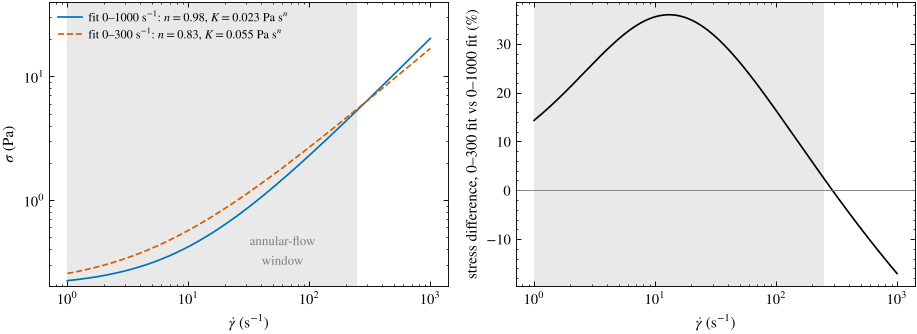

the two triplets differ by +26 % at 50 1/s, +6 % at 200 1/s and -17 % at 1000 1/s


In [15]:
fd3 = pd.read_csv(ROOT / "data" / "figure_data" / "fig03_parameter_atlas.csv", comment="#")
f3 = fd3[fd3.material.str.startswith("Used drilling fluid")].set_index("material")
for name, p in [("Used drilling fluid (fit 0-1000 1/s)", fit1000), ("Used drilling fluid (fit 0-300 1/s)", fit300)]:
    assert np.isclose(float(f3.loc[name, "n"]), p.n) and np.isclose(float(f3.loc[name, "K_Pa_s_n"]), p.K) and np.isclose(float(f3.loc[name, "sigma_y_Pa"]), p.sigma_y)
print("both triplets agree with data/figure_data/fig03_parameter_atlas.csv (the two orange points joined by the arrow in Fig. 3).")
print(f"fit 0-1000 1/s: {fit1000.describe()}")
print(f"fit 0-300  1/s: {fit300.describe()}")
print(f"ratio of consistencies K_300/K_1000 = {fit300.K / fit1000.K:.2f}  (printed: 0.055/0.023)")

gd = np.logspace(0, 3, 200)
s1000, s300 = fit1000.stress(gd), fit300.stress(gd)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8.6, 3.3))
ax1.loglog(gd, s1000, color=C["blue"], label=r"fit 0–1000 s$^{-1}$: $n=0.98$, $K=0.023$ Pa s$^n$")
ax1.loglog(gd, s300, color=C["red"], ls="--", label=r"fit 0–300 s$^{-1}$: $n=0.83$, $K=0.055$ Pa s$^n$")
ax1.axvspan(1, 250, color=C["lightgrey"], alpha=0.4, lw=0)
ax1.text(60, 0.3, "annular-flow\nwindow", fontsize=8.5, color=C["grey"], ha="center")
ax1.set(xlabel=r"$\dot\gamma$ (s$^{-1}$)", ylabel=r"$\sigma$ (Pa)", ylim=(0.2, 40))
ax1.legend(fontsize=8, loc="upper left")
ax2.semilogx(gd, 100 * (s300 / s1000 - 1), color=C["black"])
ax2.axhline(0, color=C["grey"], lw=0.6)
ax2.axvspan(1, 250, color=C["lightgrey"], alpha=0.4, lw=0)
ax2.set(xlabel=r"$\dot\gamma$ (s$^{-1}$)", ylabel="stress difference, 0–300 fit vs 0–1000 fit (%)")
fig.tight_layout()
plt.show()
print(f"the two triplets differ by {100 * (fit300.stress(50) / fit1000.stress(50) - 1):+.0f} % at 50 1/s, {100 * (fit300.stress(200) / fit1000.stress(200) - 1):+.0f} % at 200 1/s and "
      f"{100 * (fit300.stress(1000) / fit1000.stress(1000) - 1):+.0f} % at 1000 1/s")

Both triplets were fitted to the same fluid, yet they are not the same flow curve: they cross near 290 s$^{-1}$ and differ by $+26$ % at 50 s$^{-1}$ (up to 36 % near 10 s$^{-1}$) and $-17$ % at 1000 s$^{-1}$. If the fit over 0–1000 s$^{-1}$ used equal absolute weights, it would be dominated by the high-stress points (Note S6 A) and represent the annular range poorly; in any case the parameters move along the identifiability valley of Sec. VI D (notebook 03): $\sigma_y$, $K$ and $n$ trade off along a direction that the data constrain weakly, and *which point on the valley a fit returns depends on the window*. The review's conclusion (Sec. X A) is that the fit should be made over the shear rates the application experiences — the narrower window predicted the measured annular pressure loss better — and that the window must be reported with the parameters (Table XIII, "calibration window covering the operating wall shear rates").

### 7.2 A pressure-loss prediction inside and outside the window (illustration, beyond the article's numbers)

How much does the choice matter for a laminar pressure loss? We compute the pressure gradient in a 50 mm pipe for both triplets over a range of flow rates, and express the operating point by the wall shear rate.

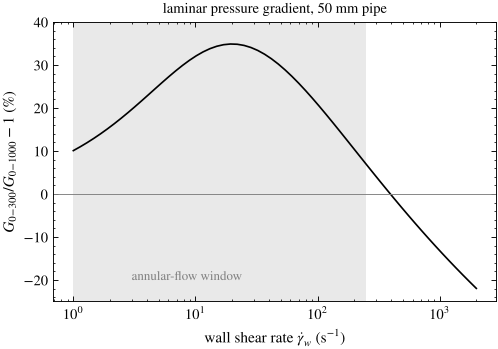

at a wall shear rate of about 100 1/s the two triplets differ by +20.4 %, at about 1000 1/s by -13.8 %


In [16]:
D_pipe = 0.05
R_pipe = D_pipe / 2
gw300 = np.logspace(0, 3.3, 60)                                                    # wall shear rate (0-300 triplet), s^-1
tw300 = fit300.stress(gw300)                                                        # corresponding wall stress
Q_range = hb_prediction.pipe_flux(tw300, R_pipe, fit300.sigma_y, fit300.K, fit300.n)   # flow rates, m^3/s
G300 = 2 * tw300 / R_pipe
G1000 = np.array([hb_prediction.pressure_gradient(q, R_pipe, fit1000.sigma_y, fit1000.K, fit1000.n) for q in Q_range])

fig, ax = plt.subplots(figsize=(5.2, 3.3))
ax.semilogx(gw300, 100 * (G300 / G1000 - 1), color=C["black"])
ax.axhline(0, color=C["grey"], lw=0.6)
ax.axvspan(1, 250, color=C["lightgrey"], alpha=0.4, lw=0)
ax.text(3, -20, "annular-flow window", fontsize=8.5, color=C["grey"])
ax.set(xlabel=r"wall shear rate $\dot\gamma_w$ (s$^{-1}$)", ylabel=r"$G_{0\!-\!300}/G_{0\!-\!1000}-1$ (%)", ylim=(-25, 40))
ax.set_title("laminar pressure gradient, 50 mm pipe", fontsize=9.5)
plt.show()
i = np.argmin(np.abs(gw300 - 100)); j = np.argmin(np.abs(gw300 - 1000))
print(f"at a wall shear rate of about 100 1/s the two triplets differ by {100 * (G300[i] / G1000[i] - 1):+.1f} %, at about 1000 1/s by {100 * (G300[j] / G1000[j] - 1):+.1f} %")

The pressure-loss difference tracks the stress difference between the two flow curves at the wall shear rate: about $+20$ % at 100 s$^{-1}$, up to $+35$ % near 20 s$^{-1}$ (both inside the annular window), and $-14$ % at 1000 s$^{-1}$. The sign reverses at the crossing of the two flow curves, so a triplet fitted on the wrong side of the operating range biases the prediction systematically. (The review's statement about which fit predicted the *measured* annular pressure loss better rests on the experiments of Saasen and Ytrehus, not on this illustration.)

### 7.3 Comparable parameters: $A=K\dot\gamma_*^n$ and $\dot\gamma_y$

Because $K$ has units that depend on $n$, "0.023 versus 0.055 Pa s$^n$" compares quantities with different units. The stress amplitude $A=K\dot\gamma_*^n$ at a reference rate inside the window, and the rate $\dot\gamma_y=(\sigma_y/K)^{1/n}$, are comparable numbers.

In [17]:
for gstar in [100.0, 250.0]:
    print(f"gdot_* = {gstar:4.0f} 1/s:  A(0-1000 fit) = {fit1000.A(gstar):.2f} Pa,  A(0-300 fit) = {fit300.A(gstar):.2f} Pa   (ratio {fit300.A(gstar) / fit1000.A(gstar):.2f}, against K ratio {fit300.K / fit1000.K:.2f})")
print(f"gdot_y = (sigma_y/K)^(1/n): {fit1000.rate_y():.1f} and {fit300.rate_y():.1f} 1/s  - the rate at which the flow stress is twice sigma_y (Nelson and Ewoldt, 2017)")
# the reparameterized law reproduces the HB law exactly
gstar = 100.0
assert np.allclose(fit300.sigma_y + fit300.A(gstar) * (gd / gstar) ** fit300.n, fit300.stress(gd), rtol=1e-12)
print("sigma_y + A (gdot/gdot_*)^n reproduces sigma_y + K gdot^n to round-off; A is in pascals whatever n is.")

gdot_* =  100 1/s:  A(0-1000 fit) = 2.09 Pa,  A(0-300 fit) = 2.47 Pa   (ratio 1.18, against K ratio 2.39)
gdot_* =  250 1/s:  A(0-1000 fit) = 5.14 Pa,  A(0-300 fit) = 5.27 Pa   (ratio 1.02, against K ratio 2.39)
gdot_y = (sigma_y/K)^(1/n): 9.1 and 4.8 1/s  - the rate at which the flow stress is twice sigma_y (Nelson and Ewoldt, 2017)
sigma_y + A (gdot/gdot_*)^n reproduces sigma_y + K gdot^n to round-off; A is in pascals whatever n is.


Written with $A$, the two fits differ by 18 % at 100 s$^{-1}$ and by 2 % at 250 s$^{-1}$, which is the honest statement of how different they are in the window; the factor 2.4 in $K$ is largely an artefact of the unit Pa s$^n$ changing with $n$. The small $\dot\gamma_y$ of a few s$^{-1}$ says that this fluid is viscous-dominated throughout the annular window: its yield stress of 0.2 Pa hardly matters for pressure loss, which is why the two-speed yield point of Sec. 3.2 could be so wrong without anyone noticing in the hydraulics.

## 8. What a shear-calibrated HB description predicts (Sec. X A, Table XIII)

| Target | What a shear calibration supports | Additional measurement |
|---|---|---|
| Pressure loss in pipes and annuli | Integral resistance at moderate and high flow (Sec. IX E) | Calibration window covering the operating wall shear rates; slip test on the pipe material; $\dot\gamma_c$ for thixotropic fluids |
| Restart after shutdown | Ideal static threshold only (Sec. IV D) | Rest-time series of breakaway stress; system compliance |
| Particle suspension and settling | Arrest criterion and drag (Sec. IX D) | Elasticity for wakes and particle interactions; settling under shear (Sec. VIII E) |
| Free-surface flow and spreading | Uniform flow of simple materials; leading force balances (Secs. IX E and IX F) | Basal slip; surface tension; deposition history; time-resolved front |
| Extrusion and filament stretching | Tensile yield onset within about 10 % in some protocols (Sec. IX C) | Extensional flow curve and failure strain |
| Injection into porous media | Form of the pressure–flow law (Sec. IX G) | Medium coefficients at the target scale; slip; jamming of the dispersed phase in narrow pores |
| Normal forces and other normal-stress effects | Not predicted: $N_1=N_2=0$ in the baseline | Normal-stress differences; elastic modulus |

Read against the three examples: Example 1 is the first row — supported, with the three conditions in the last column, and insensitive to $\sigma_y$ at high flow (which is also why the window matters more for $K$ and $n$ than for $\sigma_y$ there). Example 3 is the third row — the arrest criterion is supported as a screening estimate. Example 2 belongs to the fourth row — a leading force balance under stated assumptions (shallow, marginal, no slip). Restart of the slurry pipeline after a shutdown is *not* in the list of things Example 1 tells us: the ideal threshold $G_c=2\sigma_y/R=200$ Pa/m (notebook 05) is a lower bound, and a gelled slurry needs a rest-time series of its breakaway stress.

## 9. Glossary and nomenclature (Notes S15 C and S19)

Note S15 C defines the terms that this notebook has used loosely, and Note S19 lists every symbol with its units (it is part of the supplementary material published with the article). The repository stores the article's Table V, the principal notation, and Table IV, the dimensionless groups, as CSV files in `data/tables/`; we print them here.

| Term (Note S15 C) | Meaning |
|---|---|
| Yield stress, static | the stress required to initiate flow from rest; depends on rest time for thixotropic materials |
| Yield stress, dynamic | the extrapolated steady-flow intercept used by HB; a measured cessation threshold may depend on protocol |
| Apparent yield stress | an operationally inferred threshold; its material interpretation depends on range, boundaries and protocol |
| Engineering yield stress | a threshold defined for the time scale and tolerance of an application |
| Consistency index, $K$ | the HB prefactor; not comparable across materials with different $n$ |
| Plastic viscosity, $\mu_p$ | the Bingham slope; equal to $K$ only when $n=1$ |
| Flow (behavior) index, $n$ | the HB exponent; distinct from the local index $n'$ of the Metzner–Reed construction |
| Plug, unyielded region | a rigid region with $\mathsf D=0$ and an admissible stress $\sigma\le\sigma_y$; in regularized models, the set identified by a criterion |
| Pseudo-plug | a region in thin-film flow where the stress is only slightly above yield and the material deforms slowly in the streamwise direction |
| Regularization parameter, $m$ | the time scale of the Papanastasiou model; meaningful only as the product $m\dot\gamma_{\rm ref}$ |

The two-speed "yield point" of Sec. 3.2 is an *apparent* yield stress in this vocabulary; the intercept $\sigma_y$ of the HB fit is the *dynamic* one; and the breakaway pressure that governs restart is a *static* yield stress that depends on rest time.

In [18]:
notation = pd.read_csv(ROOT / "data" / "tables" / "tableV_notation.csv", comment="#")
groups = pd.read_csv(ROOT / "data" / "tables" / "tableIV_dimensionless_groups.csv", comment="#")
print(f"Table V (principal notation): {len(notation)} symbols;  Table IV (dimensionless groups): {len(groups)} groups")
with pd.option_context("display.max_colwidth", 70, "display.width", 160):
    print(notation.to_string(index=False))
    print()
    print(groups.to_string(index=False))


Table V (principal notation): 11 symbols;  Table IV (dimensionless groups): 6 groups
       symbol                                   meaning si_unit                                         remarks
          σ_y                              yield stress      Pa also τ_0, τ_y; drilling “YP” is a Bingham value
            K                               consistency  Pa s^n                           also k, m; μ_p if n=1
            n                                flow index       –           exponent of the rate-dependent stress
           γ̇                                shear rate    s^-1                                     γ̇=√(2 D:D)
            D                rate-of-deformation tensor    s^-1                                  D=½(∇ u+∇ u^T)
         τ, σ            extra and total stress tensors      Pa                                        σ=-p I+τ
            σ            shear stress; stress magnitude      Pa                                      σ=√(½ τ:τ)
σ_E, N_1, N_2 tensi

## 10. Try it yourself

**Exercise 1 — a published triplet in cgs and minutes.** An older paper reports $\sigma_y=120$ dyn/cm$^2$, $K=85$ dyn s$^{0.6}$/cm$^2$, $n=0.6$. A second one reports the same material as $\sigma_y=12$ Pa, $K=0.73$ Pa min$^{0.6}$. Are they consistent? Convert both to SI with `HBParams.from_units` and compare the flow stress at 10 s$^{-1}$.

*Hint:* `HBParams.from_units(120, 85, 0.6, "dyn/cm2", "s")` and `HBParams.from_units(12, 0.73, 0.6, "Pa", "min")`.

<details><summary>Solution</summary>

```python
a = HBParams.from_units(120, 85, 0.6, "dyn/cm2", "s")
b = HBParams.from_units(12, 0.73, 0.6, "Pa", "min")
print(a.describe(), "|", b.describe())
print(a.stress(10.0), b.stress(10.0))
```
Both give $\sigma_y=12$ Pa and $K\approx8.5$ Pa s$^{0.6}$ ($0.73\times60^{0.6}=8.52$), so the flow stresses at 10 s$^{-1}$ agree to within 1 % (about 45.8 Pa): the two reports are the same fit in different units. Had the second $K$ been read as Pa s$^{0.6}$, the stress at 10 s$^{-1}$ would have come out as 14.9 Pa instead of 45.8 Pa.
</details>

**Exercise 2 — half the flow rate, in psi.** Repeat Route A of Sec. 4.2 for $Q=79$ gal/min (half of Example 1). By what factor does $\Delta p$ fall, and why is it much less than 2? Express the answer in psi per 1000 ft.

*Hint:* the threshold $G_c=2\sigma_y/R$ does not change with $Q$; use `hb_prediction.pressure_gradient`.

<details><summary>Solution</summary>

```python
Q_half = 79.25 * GAL / 60
G_half = hb_prediction.pressure_gradient(Q_half, R_A, p_A.sigma_y, p_A.K, p_A.n)
dp_half = G_half * L_A
print(dp_half / PSI, dp_half / PSI / (L_ft / 1000), dp_A / dp_half, 2 * p_A.sigma_y / R_A * L_A / PSI)
```
About 43 psi (26 psi per 1000 ft) against 58 psi: a factor of 1.36, not 2, because the yield-stress threshold ($G_cL=2\sigma_yL/R=100$ kPa $=14.5$ psi) is paid whatever the flow rate, and because the viscous part grows sub-linearly with $Q$ ($n=0.7<1$).
</details>

**Exercise 3 — how well must the spread be measured?** For Example 2, what uncertainty in $R$ (in mm) gives a 10 % uncertainty in $\sigma_y$, and what uncertainty in $V$ gives the same? Then express the 23 Pa result in lbf/100 ft$^2$ and in dial degrees — would a field viscometer resolve the difference between the 350 mm and the 300 mm spreads?

*Hint:* Eq. (S27): $\mathrm{d}\sigma_y/\sigma_y=-5\,\mathrm{d}R/R=2\,\mathrm{d}V/V$.

<details><summary>Solution</summary>

```python
print(0.1 / 5 * 350, "mm", 0.1 / 2 * 5.5, "L")
print(ty_350 / LBF_100FT2, ty_350 / DIAL, ty_300 / DIAL)
```
A radius error of 7 mm (2 %) or a volume error of 0.28 L (5 %) each give 10 % in $\sigma_y$. The results are 48 and 105 lbf/100 ft$^2$, i.e. about 45 and 98 dial degrees: easily distinguished on a dial — the difficulty of the slump-flow estimate is not resolution but the fifth power and the shape assumptions.
</details>

## Key points

* $[K]=$ Pa s$^n$ depends on $n$: convert $K$ with the stress factor **and** the time factor to the power $n$ ($K_{\rm s}=K_{\rm min}60^n$; rpm $\to$ s$^{-1}$ with $1.703$), and never compare $K$ between materials of different $n$ — compare $A=K\dot\gamma_*^n$ or $\dot\gamma_y=(\sigma_y/K)^{1/n}$ instead.
* Table SVI: 1 lbf/100 ft$^2=0.4788$ Pa, one dial degree $=1.067$ lbf/100 ft$^2=0.511$ Pa, 1 rpm $=1.703$ s$^{-1}$, so a dial slope between 300 and 600 rpm is a viscosity in cP; the two-speed yield point is an apparent yield stress that can exceed $\sigma_y$ by a large factor.
* Example 1 gives $\Delta p=401$ kPa $=58.2$ psi, $\sigma_w=20.0$ Pa $=41.9$ lbf/100 ft$^2$ and $\mathrm{Re_{MR}}=776$ whether solved in SI or in the lbf–ft–s system; the mixed oilfield units themselves are not a consistent system, and lb/gal is a mass unit.
* Example 2: $\sigma_y=225\rho gV^2/(128\pi^2R^5)$ gives 23 Pa at 350 mm and 50 Pa at 300 mm; $\mathrm{d}\sigma_y/\sigma_y=-5\,\mathrm{d}R/R$, independent of $K$ and $n$, and valid only under the shallow, marginal, no-slip assumptions.
* Example 3: $\sigma_y\simeq3.51$ Pa holds a 5 mm cutting ($Y_g>0.143$, $Y_R>0.0953$); a dimensionless group is unit-independent, which is a test of the conversions.
* For a drilling fluid the fitting window moves the triplet along the identifiability valley ($n$: 0.98 $\to$ 0.83, $K$: 0.023 $\to$ 0.055 Pa s$^n$) and changes the predicted laminar pressure loss by tens of per cent inside the annular window in our illustration; fit over the shear rates of the application and report the window (Table XIII).
* A shear calibration supports pressure loss at moderate and high flow, an arrest criterion and leading force balances; restart, normal forces and extensibility need separate measurements.

## References

The review and its repository:
* Y. Wang (2026). A century of the Herschel–Bulkley model (1926–2026): Widespread use, community achievements, predictive capability, and engineering implications. Manuscript submitted to the *Journal of Rheology*; code and data: https://github.com/ktwyw/hb-centenary-review

* American Petroleum Institute (2017). *Recommended Practice on the Rheology and Hydraulics of Oil-Well Drilling Fluids, API RP 13D*, 7th ed. (American Petroleum Institute, Washington, DC).
* Beris, A. N., Tsamopoulos, J. A., Armstrong, R. C., and Brown, R. A. (1985). Creeping motion of a sphere through a Bingham plastic. *Journal of Fluid Mechanics* **158**, 219–244. https://doi.org/10.1017/s0022112085002622
* Kelessidis, V. C., Maglione, R., Tsamantaki, C., and Aspirtakis, Y. (2006). Optimal determination of rheological parameters for Herschel–Bulkley drilling fluids and impact on pressure drop, velocity profiles and penetration rates during drilling. *Journal of Petroleum Science and Engineering* **53**, 203–224. https://doi.org/10.1016/j.petrol.2006.06.004
* Metzner, A. B., and Reed, J. C. (1955). Flow of non-Newtonian fluids — correlation of the laminar, transition, and turbulent-flow regions. *AIChE Journal* **1**, 434–440. https://doi.org/10.1002/aic.690010409
* Nelson, A. Z., and Ewoldt, R. H. (2017). Design of yield-stress fluids: a rheology-to-structure inverse problem. *Soft Matter* **13**, 7578–7594. https://doi.org/10.1039/C7SM00758B
* Roussel, N., and Coussot, P. (2005). "Fifty-cent rheometer" for yield stress measurements: From slump to spreading flow. *Journal of Rheology* **49**, 705–718. https://doi.org/10.1122/1.1879041
* Saasen, A., and Ytrehus, J. D. (2020). Viscosity models for drilling fluids — Herschel–Bulkley parameters and their use. *Energies* **13**, 5271. https://doi.org/10.3390/en13205271

### Further reading

* Abou-Kassem, A. J., Bizhani, M., and Kuru, E. (2023). A review of methods used for rheological characterization of yield-power-law (YPL) fluids and their impact on the assessment of frictional pressure loss in pipe flow. *Geoenergy Science and Engineering* **229**, 212050. https://doi.org/10.1016/j.geoen.2023.212050
* Frigaard, I. A., Paso, K. G., and de Souza Mendes, P. R. (2017). Bingham's model in the oil and gas industry. *Rheologica Acta* **56**, 259–282. https://doi.org/10.1007/s00397-017-0999-y
* Pashias, N., Boger, D. V., Summers, J., and Glenister, D. J. (1996). A fifty cent rheometer for yield stress measurement. *Journal of Rheology* **40**, 1179–1189. https://doi.org/10.1122/1.550780
* Skadsem, H. J., and Saasen, A. (2019). Concentric cylinder viscometer flows of Herschel–Bulkley fluids. *Applied Rheology* **29**, 173–181. https://doi.org/10.1515/arh-2019-0015
* Zhaidarbek, B., Tleubek, A., Berdibek, G., and Wang, Y. (2023). Analytical predictions of concrete pumping: Extending the Khatib–Khayat model to Herschel–Bulkley and modified Bingham fluids. *Cement and Concrete Research* **163**, 107035. https://doi.org/10.1016/j.cemconres.2022.107035